# Task 3 · Midterm Project: Bank Marketing, term deposit
**Author:** Baizhan  **SEED:** 3101

The notebook runs top to bottom with Restart & Run All.

## Stage 1 · Framing

**Business question.** The bank phones clients to sell a term deposit. In one wave the call centre can phone only 10% of the list. The model must rank clients by the probability of "yes" so that the called 10% contains as many buyers as possible. Scoring happens before any call.

**Metric.** Only the ranking matters because exactly the top 10% are called. Main metrics: ROC-AUC and average precision; for the decision: precision@10%, recall@10% and lift over random calling. Accuracy is not used because a model that always says "no" already gets 88.7%.

**Train vs test columns.** `y` and `duration` exist only in train. `y` is the answer we predict. `duration` is the length of the call, which is known only after the call is made, but scoring is done before any call. Consequence: `duration` must not be a feature (it would inflate the scores and could not be computed in real use). `id` is in both files but is only an identifier, so it is dropped as well.

In [18]:
import sys, os, sklearn, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

SEED = 3101
print(sys.version)
print("sklearn", sklearn.__version__, "numpy", np.__version__, "pandas", pd.__version__, "SEED", SEED)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(train.shape, test.shape)
print("only in train:", set(train.columns) - set(test.columns))
print("only in test:", set(test.columns) - set(train.columns))

3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
sklearn 1.7.2 numpy 2.3.4 pandas 2.3.3 SEED 3101
(32940, 22) (8236, 20)
only in train: {'y', 'duration'}
only in test: set()


## Stage 2 · EDA

**Class balance.** "yes" = 11.27% (about 3 711 of 32 940 rows), "no" = 88.73%. A classifier that always answers "no" gets accuracy 0.887, so accuracy is misleading: it looks high while the model finds no buyers at all.

**"Missing" values and the sentinel.** "unknown" appears in: default 6 871 (20.9%), education 1 401 (4.3%), housing 794 (2.4%), loan 794 (2.4%), job 275 (0.8%), marital 64 (0.2%). `pdays == 999` in 31 694 rows (96.2%); it means "not contacted before", not 999 real days.

**Row order.** The month changes between neighbouring rows 26 442 times out of 32 939 transitions, so the rows are shuffled and carry no time order. The CV with `shuffle=True` is therefore fine, but it also means the split cannot respect time.

**Plots.**
1. "yes" rate by `poutcome`: ___ for "success" vs ___ for "nonexistent" (from the plot cell).
2. `euribor3m` by y: median ___ for "yes" vs ___ for "no" (from the printout).

**Summary.** Most related features: ___ (poutcome, euribor3m, nr.employed, month look strongest, check against your numbers).

yes share: 0.11265938069216758 | yes rows: 3711 | majority accuracy: 0.8873406193078324
           count     share
job          275  0.008349
marital       64  0.001943
education   1401  0.042532
default     6871  0.208591
housing      794  0.024104
loan         794  0.024104
pdays==999: 31694 0.9621736490588949
month changes: 26442 of 32939
poutcome
failure        0.140309
nonexistent    0.088132
success        0.647788
Name: y, dtype: float64


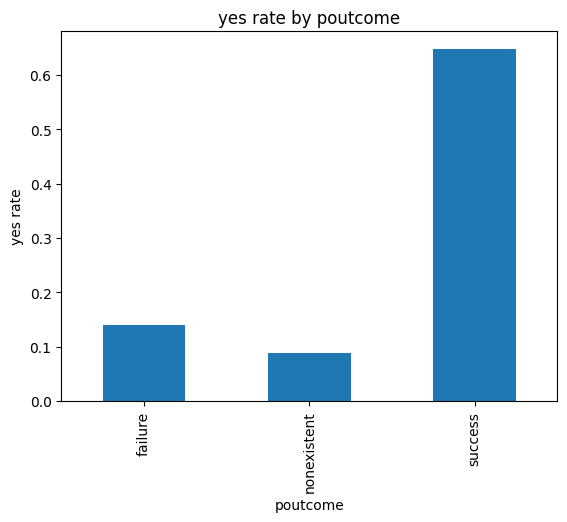

y
no     4.857
yes    1.266
Name: euribor3m, dtype: float64


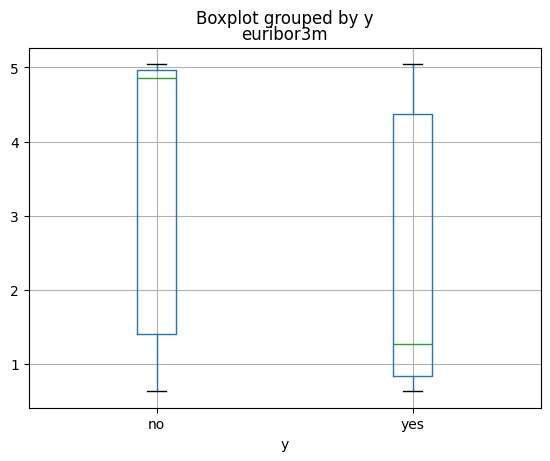

In [19]:
y = (train["y"] == "yes").astype(int)
print("yes share:", y.mean(), "| yes rows:", y.sum(), "| majority accuracy:", 1 - y.mean())

obj = train.select_dtypes(exclude="number").columns.drop("y")
u = (train[obj] == "unknown").sum().loc[lambda s: s > 0]
print(pd.DataFrame({"count": u, "share": u / len(train)}))
print("pdays==999:", (train["pdays"] == 999).sum(), (train["pdays"] == 999).mean())
print("month changes:", (train["month"] != train["month"].shift()).sum(), "of", len(train) - 1)

rate = train.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean())
print(rate)
rate.plot.bar(); plt.ylabel("yes rate"); plt.title("yes rate by poutcome"); plt.show()
print(train.groupby("y")["euribor3m"].median())
train.boxplot(column="euribor3m", by="y"); plt.show()

## Stage 3 · Validation design

`train.csv` is split into **dev** (80%) and **hold-out** (20%). The hold-out is untouched until Stage 7. Comparison and tuning use `StratifiedKFold(n_splits=5, shuffle=True, random_state=3101)` on dev only.

- *Why stratified:* only 11.3% are "yes"; stratification keeps that share almost equal in every fold.
- *Why 5 folds:* each validation fold still has about 5 270 rows (about 590 "yes"), so scores are stable, and tuning stays fast. (Write your own reason if you chose 10.)
- *Why shuffle:* the rows have no time order (see Stage 2).
- *Spread rule:* if two models differ by less than the fold standard deviation, I do not declare a winner.

| Set | Rows | "yes" share |
|---|---|---|
| dev | ___ | ___ |
| hold-out | ___ | ___ |

In [22]:
X = train.drop(columns=["y", "duration", "id"])
X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_dev.shape, X_hold.shape, y_dev.mean(), y_hold.mean())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_scores(model, scoring=("roc_auc", "average_precision")):
    r = cross_validate(model, X_dev, y_dev, cv=cv, scoring=list(scoring), n_jobs=1)
    return {m: (round(r[f"test_{m}"].mean(), 4), round(r[f"test_{m}"].std(), 4)) for m in scoring}

(26352, 19) (6588, 19) 0.11266697024893746 0.11262902246508803


## Stage 4 · Preprocessing inside a pipeline

| Column type | Columns | Treatment | Reason |
|---|---|---|---|
| `pdays` | pdays | 999 treated as missing, median imputation + missing indicator + scaling | 999 is a code for "never contacted", not a number of days; the indicator keeps that information |
| Numeric | age, campaign, previous, economic indicators | median imputation + StandardScaler | needed for logistic regression, SVM; harmless for trees |
| Categorical | job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome | OneHotEncoder(handle_unknown="ignore") | no natural order; unseen categories will not crash |
| "unknown" | categorical columns | A: own category; B: replaced by the most frequent value | "unknown" may itself carry signal (e.g. default) |

**Leakage protection.** All fitted steps are inside one `Pipeline`, so `cross_validate` fits them on the training part of each fold only. Evidence: the scaler means inside a fold differ from the whole-dev means (cell below).

**Comparison (LogisticRegression, ROC-AUC mean ± std):** A = ___ ± ___, B = ___ ± ___. Difference = ___, fold std = ___, so the difference is (inside / outside) the noise. Choice: ___, because ___.

**Raw input.** The pipeline takes the raw `test.csv` columns (without `id` and `duration`) with no manual step; checked in the last line of the cell below.

In [23]:
num_cols = [c for c in X.select_dtypes("number").columns if c != "pdays"]
cat_cols = list(X.select_dtypes(exclude="number").columns)

def build_preprocessor(unknown="category"):
    pdays = Pipeline([("imp", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())])
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    if unknown == "category":
        cat = OneHotEncoder(handle_unknown="ignore")
    else:
        cat = Pipeline([("imp", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
                        ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("pdays", pdays, ["pdays"]), ("num", num, num_cols), ("cat", cat, cat_cols)])

base = Pipeline([("prep", build_preprocessor()), ("clf", LogisticRegression(max_iter=2000))])

# leakage evidence
tr_idx, _ = next(cv.split(X_dev, y_dev))
base.fit(X_dev.iloc[tr_idx], y_dev.iloc[tr_idx])
sc = base.named_steps["prep"].named_transformers_["num"].named_steps["sc"]
print(pd.DataFrame({"fold-train mean": sc.mean_, "whole dev mean": X_dev[num_cols].mean().values},
                   index=num_cols).head(8))

for mode in ["category", "nan"]:
    p = Pipeline([("prep", build_preprocessor(mode)), ("clf", LogisticRegression(max_iter=2000))])
    print(mode, cv_scores(p))

print(base.predict_proba(test[X.columns].head())[:, 1])   # raw test columns

                fold-train mean  whole dev mean
age                   40.090508       40.059540
campaign               2.574973        2.567054
previous               0.174090        0.176837
emp.var.rate           0.081405        0.075448
cons.price.idx        93.575997       93.575539
cons.conf.idx        -40.478246      -40.502899
euribor3m              3.617455        3.610806
nr.employed         5166.784043     5166.533128
category {'roc_auc': (np.float64(0.7936), np.float64(0.0087)), 'average_precision': (np.float64(0.4568), np.float64(0.0172))}
nan {'roc_auc': (np.float64(0.7934), np.float64(0.0089)), 'average_precision': (np.float64(0.4558), np.float64(0.0171))}
[0.07289864 0.03321786 0.04328425 0.06224736 0.02343843]


## Stage 5 · Baselines (same folds)

| Model | Accuracy | ROC-AUC | Average precision |
|---|---|---|---|
| Dummy (prior) | ___ ± ___ | ___ ± ___ | ___ ± ___ |
| LogisticRegression | ___ ± ___ | ___ ± ___ | ___ ± ___ |

The dummy model has accuracy about 0.887 but ROC-AUC 0.5, so accuracy is misleading here. Every later model must beat LogisticRegression (ROC-AUC ___ ± ___).

In [24]:
three = ("accuracy", "roc_auc", "average_precision")
dummy = Pipeline([("prep", build_preprocessor()), ("clf", DummyClassifier(strategy="prior"))])
print("dummy ", cv_scores(dummy, three))
print("logreg", cv_scores(base, three))

dummy  {'accuracy': (np.float64(0.8873), np.float64(0.0001)), 'roc_auc': (np.float64(0.5), np.float64(0.0)), 'average_precision': (np.float64(0.1127), np.float64(0.0001))}
logreg {'accuracy': (np.float64(0.8994), np.float64(0.0017)), 'roc_auc': (np.float64(0.7936), np.float64(0.0087)), 'average_precision': (np.float64(0.4568), np.float64(0.0172))}
